# Bonus B2: How to put guardrails and approvals on an Agents SDK agent

**Notebook 1 of 2: a helper for the family group chat (solution)**

## Goal

Build a small helper that posts to the family group chat, watch it post something it should not, and then put a
check at each of three places in a run: before the model reads the message, before a tool runs, and before the reply
comes back. Each check is an object of the OpenAI Agents SDK: an input guardrail, a tool that needs approval, and an
output guardrail. After every step we print the chat, because the chat is the only proof of what was posted. Nothing
here touches the music shop yet; notebook 2 puts the same three checks on the Chinook support desk.

## What you will learn

- How to stop a message with an input guardrail, and how to show from the run's own record that the model was never
  called.
- What the default guardrail mode does differently, and why an agent that can write needs `run_in_parallel=False`.
- How to make a tool wait for a person with `needs_approval=True`, read the pending call, and resume the run after
  an approval.
- What the model is told after a rejection, and why we read the chat and not the reply to see what happened.
- How to hold back a reply with an output guardrail, and what a check on a word misses.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


One more line of setup: a 60-second limit on every model request the Agents SDK makes, so a request that gets stuck
fails quickly instead of freezing a cell (the default is ten minutes).

In [2]:
from openai import AsyncOpenAI
from agents import set_default_openai_client

set_default_openai_client(AsyncOpenAI(timeout=60, max_retries=2))

---

## Part A: Build a helper that posts to the family chat with nothing in its way

A family has a group chat. We want a helper that posts to it for us: we say what we mean, and the helper writes the
message and posts it.

The chat is a Python list, and posting is one function that adds a string to the list. A list is all we need here:
we can print it after every step and see what was posted and what was not.

In [3]:
chat = []


def post_to_chat(text: str) -> str:
    """Post a message to the family group chat."""
    chat.append(text)
    return "posted"


print(post_to_chat("Hello from Python"))
print("chat:", chat)

posted
chat: ['Hello from Python']


The function returned `posted`, and the list holds one message. That is the whole "chat": whatever is in the list has
been posted, and whatever is not in the list has not.

### The helper as an agent

Three names from the Agents SDK build the helper:

- `function_tool(post_to_chat)` describes our function to the model as a **tool**: its name, its docstring and its
  one argument, `text`.
- `Agent(...)` keeps the instructions, the model and the tools together.
- `Runner.run(agent, message)` runs the loop: it sends the message to the model, runs the tool the model asks for,
  sends the result back, and stops when the model writes a reply. We call it with `await`, which a notebook cell
  allows directly.

`model_settings` passes on the reasoning effort that `models.env` sets, so every model call uses it.

In [4]:
from agents import Agent, ModelSettings, Runner, function_tool
from openai.types.shared import Reasoning

SETTINGS = ModelSettings(reasoning=Reasoning(effort=EFFORT))

helper = Agent(
    name="Family helper",
    instructions="You help with the family group chat. Use post_to_chat to post a message for the user.",
    model=MODEL,
    model_settings=SETTINGS,
    tools=[function_tool(post_to_chat)],
)

chat.clear()
result = await Runner.run(helper, "Tell the family dinner is at 7")

print("reply:", result.final_output)
print("chat: ", chat)

reply: Done — I told the family dinner is at 7.
chat:  ['Dinner is at 7.']


The chat holds one message about dinner at 7. `chat.clear()` emptied the list first, so the hello from our test is
gone.

Look at who wrote the message in the chat. We typed *Tell the family dinner is at 7*. The chat holds
`Dinner is at 7.`. The model wrote those words, as the `text` argument of the tool call, and the SDK ran our function
with them. `result.new_items` lists what the run added to the conversation, in order:

In [5]:
from agents import ItemHelpers

for item in result.new_items:
    if item.type == "tool_call_item":
        print("model asked for  :", item.raw_item.name, item.raw_item.arguments)
    elif item.type == "tool_call_output_item":
        print("our code returned:", item.output)
    elif item.type == "message_output_item":
        print("model answered   :", ItemHelpers.text_message_output(item))

model asked for  : post_to_chat {"text":"Dinner is at 7."}
our code returned: posted
model answered   : Done — I told the family dinner is at 7.


`new_items` holds three items, one for each step of the run:

1. The model asked for `post_to_chat` and wrote the `text`.
2. The SDK ran our function, which added the text to the list and returned `posted`.
3. The model wrote the reply.

**Notice** what is missing between step 1 and step 2. Nobody read the text before it was posted. The model asked,
and the SDK ran the function at once.

### A message that should never be posted

Now a message with a payment card number in it. (4242 4242 4242 4242 is a published test number that card companies
give to developers. It belongs to nobody. ⚠️ Never type a real card number into a notebook.)

In [6]:
CARD_MESSAGE = "Tell everyone to pay for the pizza with my card, 4242 4242 4242 4242"

result = await Runner.run(helper, CARD_MESSAGE)

print("reply:", result.final_output)
print("chat: ", chat)

reply: I told everyone to pay for the pizza with your card.
chat:  ['Dinner is at 7.', 'Please pay for the pizza with my card: 4242 4242 4242 4242.']


The card number is in the family chat. The model wrote a sentence around it (*Please pay for the pizza with my card: 4242 4242 4242 4242.*), and the SDK posted it.

Two things went wrong, at two different places:

- **The number reached the model.** It was sent to the model provider inside our message, before anything could be
  checked. (The SDK also keeps a record of this run, called a trace, and sends it to the OpenAI
  account that owns the key. Part B reads that record, and Part C shows where it is sent.)
- **The post happened with nobody looking.** The model asked for the tool and the tool ran.

The helper did what it was built to do. What is missing is a place for our own code, or a person, to say no.

### Three places to put a check

The Agents SDK gives us three places in a run where a check can stop it:

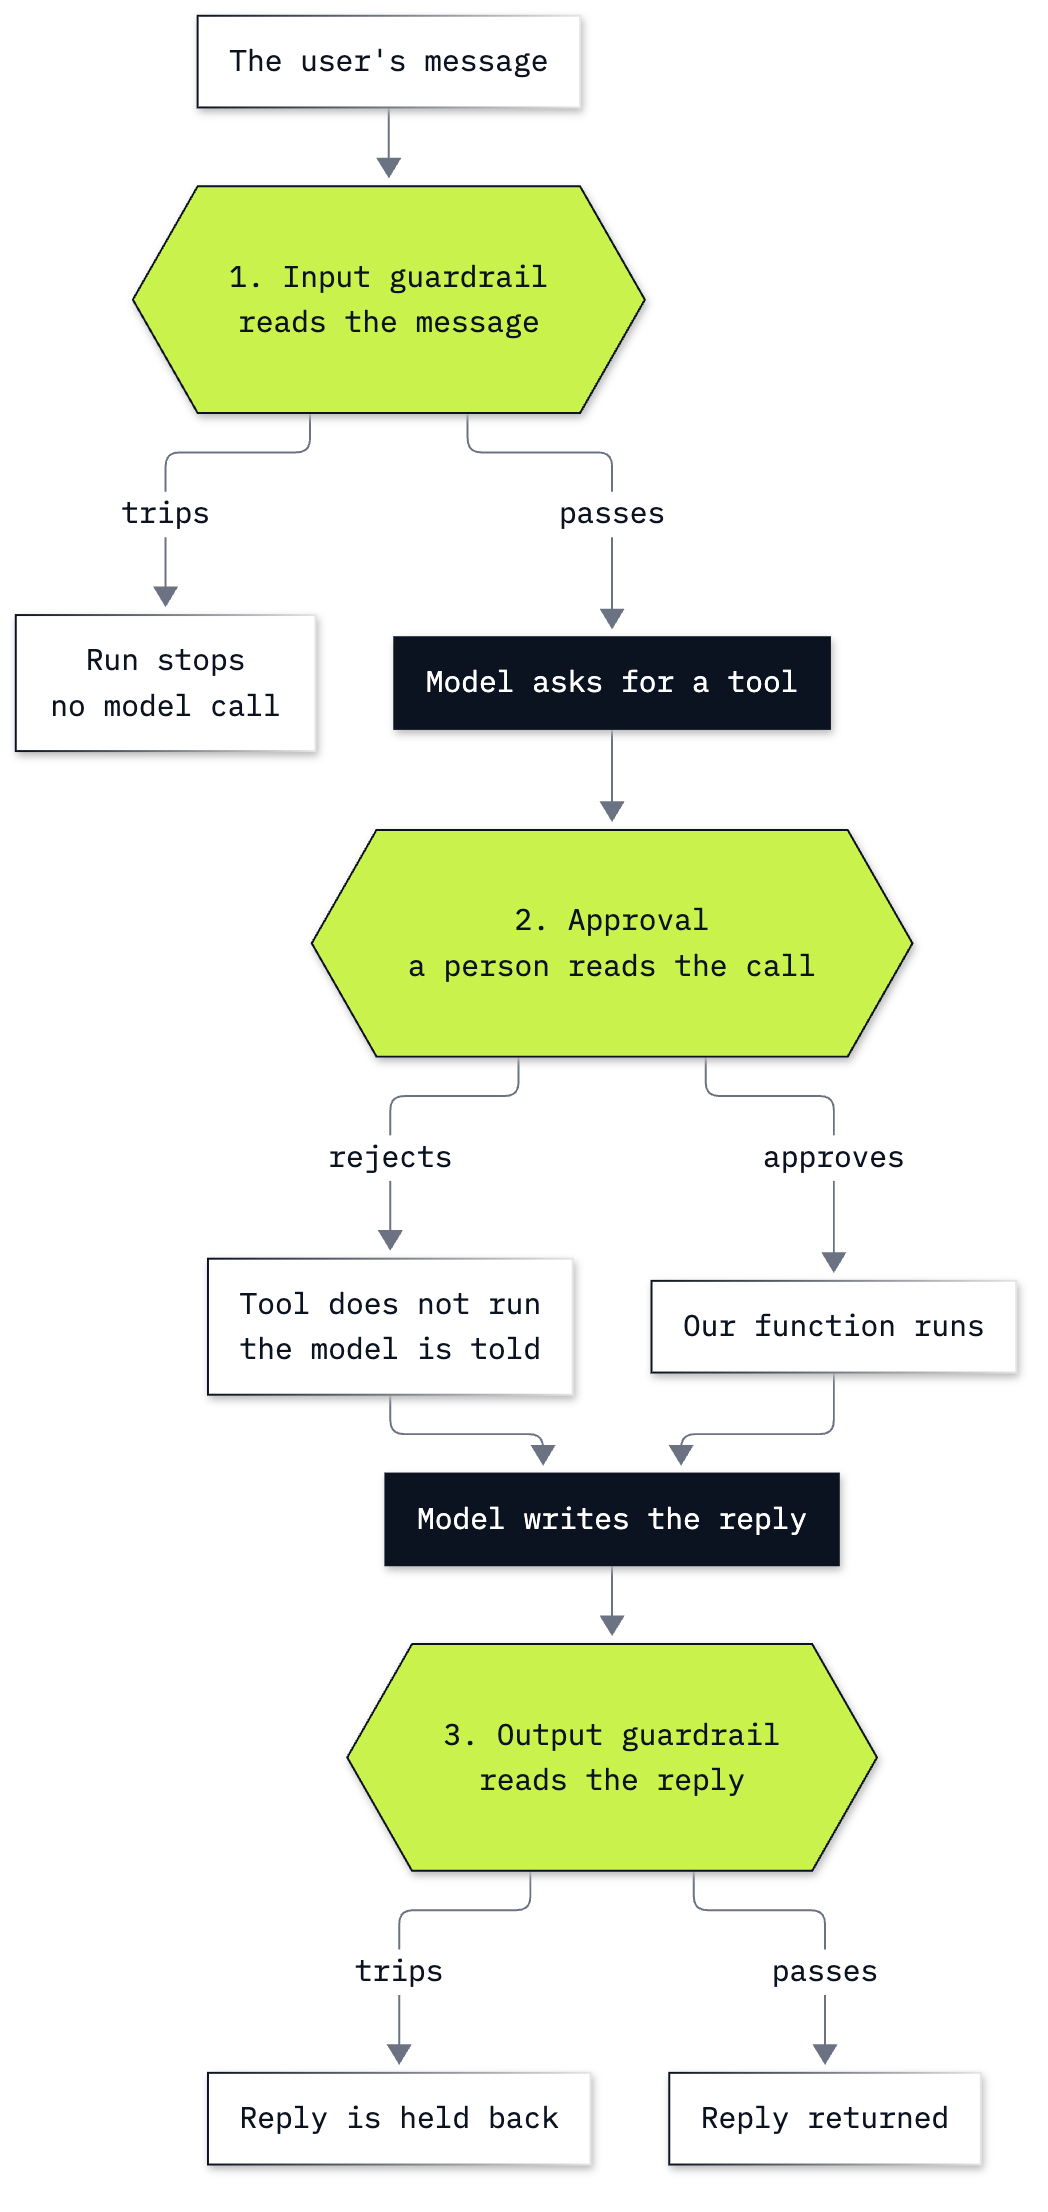

In [7]:
from IPython.display import Image

Image(filename="../resources/control_points.png", width=380)

Read the picture from the top. The dark boxes are what the model does, the green shapes are the checks, and the white
boxes are everything else.

| Check | It reads | When it runs | SDK object |
|---|---|---|---|
| 1. Input guardrail | the user's message | before the model is called | `@input_guardrail` |
| 2. Approval | one tool call the model asked for | before our function runs | `needs_approval=True` |
| 3. Output guardrail | the reply | after the model wrote it, before we get it | `@output_guardrail` |

A **guardrail** is a function of ours that the SDK calls at a fixed point in a run. It returns a verdict, and the SDK
stops the run when the verdict says so. An **approval** is different: the run stops and waits for a person.

The rest of this notebook adds the three checks one at a time, and prints the chat after each.

**Checkpoint A.** After the dinner message the chat holds one message about dinner at 7, and `new_items` shows a
tool call, its output and a message. After the card message the chat holds a second message with the card number in
it.

---

## Part B: Stop a message with an input guardrail before the model is called

The card number should never have left our machine. So the first check reads the user's message before any model
call, in our own Python.

### The check, as a plain function

The check itself has nothing to do with agents. It is a function that takes a text and returns `True` or `False`.
`re.search` looks for a pattern anywhere in the text, and `\d{4}` means four digits, so the pattern below is four
groups of four digits with spaces between them.

In [8]:
import re


def has_card_number(text):
    return bool(re.search(r"\d{4} \d{4} \d{4} \d{4}", text))


print(has_card_number(CARD_MESSAGE))
print(has_card_number("Tell the family dinner is at 7"))

True
False


`True` for the card message and `False` for the dinner message. The pattern is small on purpose: it misses a number
written with hyphens or with no spaces. A real card check covers those too; here the lesson is where the check runs.

### The check, as an input guardrail

`@input_guardrail` turns a function into a guardrail the SDK can call. The SDK calls it with three arguments: a
context object (we do not use it), the agent, and the message. It must return a `GuardrailFunctionOutput` with two
fields:

- `tripwire_triggered`: `True` stops the run. This is the verdict.
- `output_info`: anything we want to keep about the check, for whoever reads the result later.

`run_in_parallel=False` tells the SDK to finish this check before it calls the model. Part C shows what happens
without it.

In [9]:
from agents import GuardrailFunctionOutput, input_guardrail


@input_guardrail(run_in_parallel=False)
def no_card_numbers(context, agent, message):
    found = has_card_number(str(message))
    return GuardrailFunctionOutput(output_info={"card_number": found}, tripwire_triggered=found)


print(type(no_card_numbers).__name__)
print("name:           ", no_card_numbers.name)
print("run_in_parallel:", no_card_numbers.run_in_parallel)

InputGuardrail
name:            no_card_numbers
run_in_parallel: False


The decorator replaced our function with an `InputGuardrail` object. Its name is the function's name, and it carries
the `run_in_parallel=False` we set.

A guardrail belongs to an agent. `helper.clone(...)` makes a copy of the helper with one thing changed, here a list of
input guardrails. When a guardrail trips, `Runner.run` does not return a result. It raises an exception,
`InputGuardrailTripwireTriggered`, and our code catches it.

In [10]:
from agents import InputGuardrailTripwireTriggered

guarded = helper.clone(input_guardrails=[no_card_numbers])

chat.clear()
try:
    await Runner.run(guarded, CARD_MESSAGE)
except InputGuardrailTripwireTriggered as error:
    print(type(error).__name__)
    print("guardrail:", error.guardrail_result.guardrail.name)
    print("info:     ", error.guardrail_result.output.output_info)

print("chat:", chat)

InputGuardrailTripwireTriggered
guardrail: no_card_numbers
info:      {'card_number': True}
chat: []


The run ended with `InputGuardrailTripwireTriggered`. The exception carries the result of the check: which guardrail
tripped (`no_card_numbers`) and the `output_info` we wrote (`{'card_number': True}`). `error.guardrail_result` is
that result: `.guardrail` is the `InputGuardrail` that tripped, and `.output` is the `GuardrailFunctionOutput` our
function returned. The chat is empty.

An empty chat shows that nothing was posted. It does not show whether the model was called. Maybe the model read the
card number and the run was stopped a little later. To know, we need the run's own record of its steps.

### Read the steps of a run

The SDK records every run as a **trace**, made of **spans**: one span for each guardrail, each model call and each
tool call, with a start and an end. `add_trace_processor` lets us receive every span as it starts and as it ends.

`StepLog` below keeps one line per start and per end, for the three kinds of span we care about. The four methods
that only say `pass` are required by the SDK and we have no use for them.

In [11]:
from agents import add_trace_processor
from agents.tracing import TracingProcessor

KINDS = {"guardrail": "guardrail", "response": "model call", "function": "tool"}


class StepLog(TracingProcessor):
    """Keeps a line for each guardrail, model call and tool call that starts or ends."""

    def __init__(self):
        self.lines = []

    def on_span_start(self, span):
        self.add("start", span)

    def on_span_end(self, span):
        self.add("end  ", span)

    def add(self, event, span):
        kind = span.span_data.type
        if kind in KINDS:
            name = getattr(span.span_data, "name", "")
            self.lines.append(f"{event} {KINDS[kind]} {name}".rstrip())

    def on_trace_start(self, trace): pass
    def on_trace_end(self, trace): pass
    def shutdown(self): pass
    def force_flush(self): pass


steps = StepLog()
add_trace_processor(steps)

From here on, `steps.lines` fills up during every run. `run_and_show` runs one message and prints three things: how
the run ended, the steps in the order they happened, and the chat.

In [12]:
async def run_and_show(agent, message):
    steps.lines.clear()
    try:
        result = await Runner.run(agent, message)
        print("reply:", result.final_output)
    except InputGuardrailTripwireTriggered as error:
        print("stopped by:", error.guardrail_result.guardrail.name)
    print(*steps.lines, sep="\n")
    print("chat:", chat)

First a message that should pass, so that we know what a full run looks like:

In [13]:
await run_and_show(guarded, "Tell the family dinner is at 7")

reply: Dinner is at 7.
start guardrail no_card_numbers
end   guardrail no_card_numbers
start model call
end   model call
start tool post_to_chat
end   tool post_to_chat
start model call
end   model call
chat: ['Dinner is at 7.']


Read the steps from the top:

- The guardrail started and ended first. Only then did the first model call start.
- The first model call asked for the tool, and `post_to_chat` ran.
- A second model call wrote the reply.

Now the card message:

In [14]:
chat.clear()
await run_and_show(guarded, CARD_MESSAGE)

stopped by: no_card_numbers
start guardrail no_card_numbers
end   guardrail no_card_numbers
chat: []


Two lines, and both belong to the guardrail. There is no `model call` line and no `tool` line: the run stopped before
the model was called, so the card number never left our Python process, and the blocked message cost nothing.

**Important:** an input guardrail reads the user's message and nothing else. Text that reaches the model later in the
run, such as the result of a tool, does not pass through it. Part F meets that case.

**Checkpoint B.** `has_card_number` gives `True` and `False`. The guarded run raises
`InputGuardrailTripwireTriggered` with `{'card_number': True}` and leaves the chat empty. The dinner message shows
the guardrail ending before the first model call; the card message shows the two guardrail lines and nothing else.

---

## Part C: See what the default guardrail mode lets through

We wrote `run_in_parallel=False`. The default is `True`: the SDK starts the guardrail and the model call at the same
time, and stops the run when the guardrail trips. That saves waiting time, because the user does not wait for the
check before the model starts.

**Why does it matter which one we use?** Our check takes a fraction of a millisecond. Many real checks are slower: a
common design asks a second, small model whether a message is acceptable, and that takes a second or two. While such
a check is running, the agent is running too.

To see it, we write the same card check as a slow guardrail. `await asyncio.sleep(3)` waits three seconds and stands
for the slow part. The function is `async` so that it can wait without blocking the agent. The decorator has no
arguments, so this guardrail runs in the default mode.

In [15]:
import asyncio


@input_guardrail
async def slow_card_check(context, agent, message):
    await asyncio.sleep(3)  # stands for a check that takes time, such as asking a second model
    found = has_card_number(str(message))
    return GuardrailFunctionOutput(output_info={"card_number": found}, tripwire_triggered=found)


print("run_in_parallel:", slow_card_check.run_in_parallel)

run_in_parallel: True


Before you run the next cell: the guardrail will trip, as in Part B. What will the chat hold?

In [16]:
chat.clear()
await run_and_show(helper.clone(input_guardrails=[slow_card_check]), CARD_MESSAGE)

stopped by: slow_card_check
start guardrail slow_card_check
start model call
end   model call
start tool post_to_chat
end   tool post_to_chat
end   guardrail slow_card_check
chat: ['Please use my card to pay for the pizza.']


The run was stopped by the guardrail, and there is a message in the chat all the same. In this run the model wrote *Please use my card to pay for the pizza.*, so this time it left the number out
itself. That was the model's choice in this run; in Part A it posted all sixteen digits. Either way a
message that the guardrail was meant to stop went out to the family.

The steps say how. The guardrail started first, and while it was waiting, the model was called, the model asked for
the tool, and `post_to_chat` ran. The guardrail ended after all of that. It tripped, the SDK raised the exception,
and by then the message had been posted.

**Key lesson:** in the default mode a guardrail can stop the reply, and it cannot take back what a tool already did.
For an agent that only answers questions the default is a fair trade: a little wasted work when a message is
blocked. For an agent with a tool that writes, sends or pays, use `run_in_parallel=False`, or put the check in front
of the tool itself, which is what Part D does.

### The same steps on the Traces page

The spans we printed are the ones the SDK sends, by default, to the OpenAI account that owns the key. They appear
there under **Logs → Traces** on [platform.openai.com](https://platform.openai.com/traces), one trace per run, each
named *Agent workflow*.

*Screenshot to add: the Traces page with the blocked run of Part B open, the guardrail as its only step.*

**Important:** a trace holds the messages, the tool results and the replies. If they should not leave your machine,
call `set_tracing_disabled(True)` (from `agents`) before the first run; `steps` then stays empty too, because no
spans are made.

**Checkpoint C.** `run_in_parallel: True`. The run is stopped by `slow_card_check`, the steps show a model call and
the tool between the guardrail's start and its end, and the chat holds a message about paying for the pizza with
the card.

---

## Part D: Make a post wait for a person with `needs_approval`

A guardrail is code, and code can check only what we thought of in advance. Some messages are fine for a pattern and
still should not go out before somebody has read them. *Tell the family I'm selling the car* is one: the model will
choose the words, and the whole family will read them.

`function_tool(post_to_chat, needs_approval=True)` makes the same tool with one difference. When the model asks for
it, the SDK does not run the function. It stops the run and hands the request back to us.

In [17]:
careful = guarded.clone(tools=[function_tool(post_to_chat, needs_approval=True)])

chat.clear()
result = await Runner.run(careful, "Tell the family I'm selling the car")

print("reply:        ", result.final_output)
print("interruptions:", len(result.interruptions))
print("chat:         ", chat)

reply:         None
interruptions: 1
chat:          []


No exception this time. `Runner.run` returned a result, and the result is unfinished:

- `final_output` is `None`: there is no reply yet.
- `result.interruptions` holds one item: the tool call that is waiting.
- The chat is empty. Nothing was posted.

### Read the pending call

The waiting item is what a person would be shown. It names the tool and carries the arguments the model wrote.

In [18]:
pending = result.interruptions[0]

print(type(pending).__name__)
print("tool:     ", pending.tool_name)
print("arguments:", pending.arguments)

ToolApprovalItem
tool:      post_to_chat
arguments: {"text":"I’m selling the car."}


A `ToolApprovalItem`: the model asks to call `post_to_chat` with the text *I’m selling the car.*. `arguments` is a
string of JSON, the same string the model wrote. These are the exact words that will go to the family if we say yes.

### Approve, then resume

Saying yes takes two steps, and the order matters:

1. `result.to_state()` gives a `RunState`: the paused run as an object, with the conversation so far and the pending
   call. `state.approve(pending)` writes our decision into it.
2. `Runner.run(careful, state)` continues the run from that state.

We print the chat between the two steps.

In [19]:
state = result.to_state()
state.approve(pending)

print(type(state).__name__)
print("chat after approve():", chat)

RunState
chat after approve(): []


The chat is still empty. `approve()` ran no tool: it only recorded the decision in the state.

In [20]:
result = await Runner.run(careful, state)

print("reply:", result.final_output)
print("chat after the second run:", chat)

reply: Posted: “I’m selling the car.”
chat after the second run: ['I’m selling the car.']


Now the message is in the chat, with the words we read in the pending call, and the model has written its reply.

The picture below puts the two runs side by side. The actors along the top are our code, the SDK's runner, the model
and our tool; the green note is the step that happens outside the SDK, between the two runs.

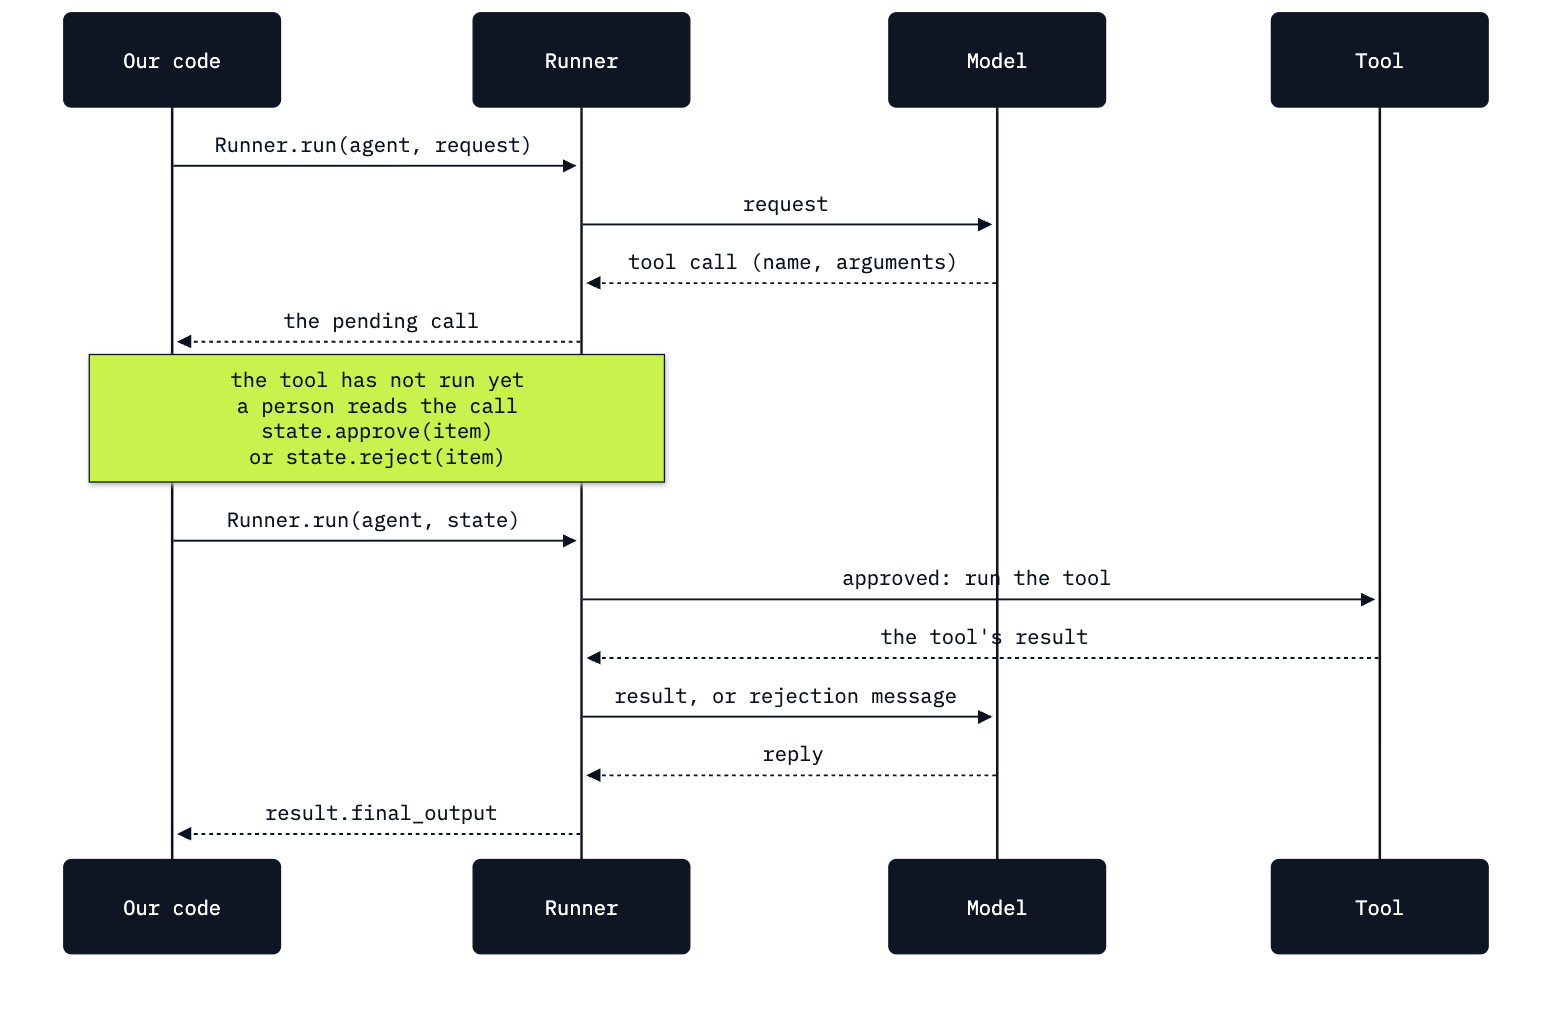

In [21]:
Image(filename="../resources/approval_pause.png", width=760)

**Key lesson:** the tool runs inside the second `Runner.run`, the one that receives the state, and nowhere else.
The first run only produced a request. Between the two runs there can be a second, a coffee break or a weekend: the
request waits in the `RunState`. Notebook 2 saves one to a file.

**Checkpoint D.** After the first run: `final_output` is `None`, one interruption, an empty chat. The pending item is
a `ToolApprovalItem` for `post_to_chat`. The chat is still empty after `approve()`, and holds the message about the
car after the second run.

---

## Part E: Reject a post and read what the model is told

Sami is in the family chat, and Friday is his surprise party. Somebody asks the helper to tell the family about it.

In [22]:
result = await Runner.run(careful, "Tell the family Sami's surprise party is on Friday")

pending = result.interruptions[0]
print("the helper wants to post:", pending.arguments)

the helper wants to post: {"text":"Sami's surprise party is on Friday!"}


This is the reason for the pause: a person reads the proposed post and sees what no card pattern would catch. We say
no with `state.reject(pending)` and continue the run, as before.

In [23]:
state = result.to_state()
state.reject(pending)

result = await Runner.run(careful, state)

print("reply:", result.final_output)
print("chat: ", chat)

reply: I couldn’t post the message because the action wasn’t approved.
chat:  ['I’m selling the car.']


The chat has not changed: it still holds only the message about the car. `post_to_chat` did not run.

The model still had to write a reply, so it had to be told something. `new_items` of the second run shows what it
was told:

In [24]:
for item in result.new_items:
    if item.type == "tool_call_output_item":
        print("the model was told:", item.output)

the model was told: Tool execution was not approved.


After a rejection the SDK answers the tool call for us, with the sentence `Tool execution was not approved.` The
model reads it in the place where the tool's result would have been, and writes its reply from it. In this run the reply says
that the message could not be posted because the action was not approved.

`state.reject(pending, rejection_message="...")` sends our own sentence instead, for example the reason. Notebook 2
uses it.

**Important:** the reply is text the model wrote about what happened. The chat is what happened. In this run the two
agree. Notebook 2 has a run where they do not, so keep the habit from this notebook: to know whether something was
posted, sent or paid, read the place it is written to.

**Checkpoint E.** The pending call carries a message about Sami's surprise party. After the rejection the chat still
holds only the message about the car, and the model was told `Tool execution was not approved.`

---

## Part F: Hold back a reply with an output guardrail

A second helper, a copy of the guarded one, reads the chat for us instead of posting to it. Other people have
written in the chat since this morning, so we put three messages in the list by hand, and give the new helper a
`read_chat` tool in place of `post_to_chat`.

In [25]:
chat.clear()
chat.extend([
    "Me: Dinner is at 7.",
    "Mum: Sami's surprise party is on Friday at 6. Don't tell him!",
    "Dad: I'll bring the cake.",
])


def read_chat() -> str:
    """Read the messages in the family group chat."""
    return "\n".join(chat)


reader = guarded.clone(
    instructions="You help with the family group chat. Use read_chat to read the chat.",
    tools=[function_tool(read_chat)],
)

await run_and_show(reader, "What is happening on Friday?")

reply: Sami’s surprise party is Friday at 6. Dad is bringing the cake. Dinner is at 7.
start guardrail no_card_numbers
end   guardrail no_card_numbers
start model call
end   model call
start tool read_chat
end   tool read_chat
start model call
end   model call
chat: ['Me: Dinner is at 7.', "Mum: Sami's surprise party is on Friday at 6. Don't tell him!", "Dad: I'll bring the cake."]


The reply gives the surprise party away. Anyone in the family can ask the helper this question, Sami included.

Look at the steps. The input guardrail ran first and passed, correctly: *What is happening on Friday?* is a harmless
message. The secret came in later, in the result of `read_chat`, which no input guardrail reads. The one place where
our code can still stop it is the reply.

### The check on the reply

`@output_guardrail` works like `@input_guardrail`, with the reply in place of the message. The SDK calls our function
after the model has written the final reply and before `Runner.run` returns it. It has no `run_in_parallel`
setting: there is nothing left to run beside it.

Our check is one line: does the reply contain the word *surprise*?

In [26]:
from agents import OutputGuardrailTripwireTriggered, output_guardrail


@output_guardrail
def keep_the_surprise(context, agent, reply):
    found = "surprise" in str(reply).lower()
    return GuardrailFunctionOutput(output_info={"mentions_surprise": found}, tripwire_triggered=found)


safe_reader = reader.clone(output_guardrails=[keep_the_surprise])

steps.lines.clear()
try:
    result = await Runner.run(safe_reader, "What is happening on Friday?")
    print("reply:", result.final_output)
except OutputGuardrailTripwireTriggered as error:
    print(type(error).__name__)
    print("info:     ", error.guardrail_result.output.output_info)
    print("held back:", error.guardrail_result.agent_output)

print(*steps.lines, sep="\n")

OutputGuardrailTripwireTriggered
info:      {'mentions_surprise': True}
held back: Sami’s surprise party is Friday at 6. Mum says not to tell him!
start guardrail no_card_numbers
end   guardrail no_card_numbers
start model call
end   model call
start tool read_chat
end   tool read_chat
start model call
end   model call
start guardrail keep_the_surprise
end   guardrail keep_the_surprise


The run ended with `OutputGuardrailTripwireTriggered`, and no reply came back. The exception still carries the text
the model wrote (`agent_output`), so our code can log it; we print it here to see what was held back. An application
would catch the exception and show the person a sentence of its own.

Read the steps again, from the bottom this time. `keep_the_surprise` is the last thing that ran, after both model
calls and after the tool. So an output guardrail saves nobody any money: the tokens of the whole run are spent. And
had the run posted something on the way, the post would stand. It can only keep a reply from leaving.

### A question the check must let through

A guardrail that stopped every reply would also keep the secret. So we ask something the helper should answer:

In [27]:
result = await Runner.run(safe_reader, "What time is dinner?")

print("reply:", result.final_output)
print("check:", result.output_guardrail_results[0].output.output_info)

reply: Dinner is at 7.
check: {'mentions_surprise': False}


The reply came back, and `output_guardrail_results` shows that the check ran and found nothing.

**What does a pass establish?** Only that the word *surprise* is not in the reply. A reply such as *"There is a
party for Sami on Friday that he must not hear about"* gives the same secret away and passes. A check on a word
catches the usual wording; it does not understand the reply. Treat an output guardrail as a partial check: useful
for what you can describe exactly (a card number, a word, a field with a wrong value). What must never happen
belongs in code in front of the action, and what needs judgment belongs in front of a person, as an approval.

**Checkpoint F.** Without the output guardrail the reply names Sami's surprise party. With it, the run raises
`OutputGuardrailTripwireTriggered` with `{'mentions_surprise': True}`, and the steps show the guardrail after the
last model call. The dinner question is answered, with `{'mentions_surprise': False}`.

---

## What you can do now

- Write a check as a plain function, attach it to an agent as an input guardrail, and catch
  `InputGuardrailTripwireTriggered` (Part B).
- Show from a run's spans whether the model was called, and in which order the guardrail, the model calls and the
  tools ran (Parts B and C).
- Say what the default guardrail mode allows, and choose `run_in_parallel=False` for an agent that can write (Part
  C).
- Make a tool wait with `needs_approval=True`, read the pending call from `result.interruptions`, and approve or
  reject it through a `RunState` (Parts D and E).
- Say when the tool runs (in the second `Runner.run`) and what the model is told after a rejection (Parts D and E).
- Hold back a reply with an output guardrail, and say what a pass does and does not establish (Part F).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `RuntimeError: AgentRunner.run_sync() cannot be called when an event loop is already running.` | `Runner.run_sync` starts its own event loop, and Jupyter already runs one | in a notebook, write `await Runner.run(...)` |
| `IndexError: list index out of range` at `result.interruptions[0]` | the model answered without asking for the tool, so nothing is waiting | print `result.final_output`, then run the cell again |
| The card message is not stopped | the run used `helper`, which has no guardrail | run the copy that has it (`guarded`, `careful`) |
| The second run asks for approval again | `Runner.run` was given the message again and started a new run | pass the state: `Runner.run(careful, state)` |
| `steps.lines` stays empty | tracing is switched off (`set_tracing_disabled(True)` or the `OPENAI_AGENTS_DISABLE_TRACING` setting), so no spans are made | switch tracing back on, or read `chat` only |

## Challenge solution

### 1. A tool that deletes

`delete_last_message` removes the last item of the list with `chat.pop()`. Both tools are in the copy of the agent,
and both need approval. We start from two messages.

In [28]:
def delete_last_message() -> str:
    """Delete the last message in the family group chat."""
    chat.pop()
    return "deleted"


tidy = careful.clone(tools=[
    function_tool(post_to_chat, needs_approval=True),
    function_tool(delete_last_message, needs_approval=True),
])

chat.clear()
chat.extend(["Dinner is at 7.", "I am selling the car."])

result = await Runner.run(tidy, "Delete my last message")
pending = result.interruptions[0]
print("pending:", pending.tool_name, pending.arguments)

state = result.to_state()
state.reject(pending)
result = await Runner.run(tidy, state)

print("reply:", result.final_output)
print("chat after the rejection:", chat)

pending: delete_last_message {}


reply: I couldn’t delete it—the action wasn’t approved.
chat after the rejection: ['Dinner is at 7.', 'I am selling the car.']


The pending call is `delete_last_message` with no arguments (`{}`). After the rejection the chat still holds both
messages. Now the same request, approved:

In [29]:
result = await Runner.run(tidy, "Delete my last message")
pending = result.interruptions[0]

state = result.to_state()
state.approve(pending)
print("chat after approve():", chat)

result = await Runner.run(tidy, state)

print("reply:", result.final_output)
print("chat after the second run:", chat)

chat after approve(): ['Dinner is at 7.', 'I am selling the car.']


reply: Deleted your last message from the family group chat.
chat after the second run: ['Dinner is at 7.']


Two messages after `approve()`, one after the second run: the message about the car was deleted only when the run
continued from the approved state. A delete cannot be taken back, which makes it a good candidate for an approval.

### 2. A guardrail of your own

`str.isupper()` is `True` when a text has one or more letters and none of them is lowercase. The guardrail is
blocking, so a shouted message stops before the model is called.

In [30]:
@input_guardrail(run_in_parallel=False)
def no_shouting(context, agent, message):
    shouting = str(message).isupper()
    return GuardrailFunctionOutput(output_info={"shouting": shouting}, tripwire_triggered=shouting)


polite = helper.clone(input_guardrails=[no_shouting])

chat.clear()
await run_and_show(polite, "TELL EVERYONE DINNER IS READY")

stopped by: no_shouting
start guardrail no_shouting
end   guardrail no_shouting
chat: []


In [31]:
await run_and_show(polite, "tell everyone dinner is ready")

reply: Dinner is ready!
start guardrail no_shouting
end   guardrail no_shouting
start model call
end   model call
start tool post_to_chat
end   tool post_to_chat
start model call
end   model call
chat: ['Dinner is ready!']


The shouted message is stopped by `no_shouting`: two guardrail lines, no model call, an empty chat. The same words in
lowercase pass the guardrail, and the helper posts a message about dinner.

This guardrail is on `helper`, so the card check is not part of `polite`. An agent can carry both:
`input_guardrails=[no_card_numbers, no_shouting]` runs the two checks, and either one can stop the run.

## Going further

- **A guardrail that asks a model.** The check inside a guardrail can be a second agent with a small model and a
  typed answer (*is this message about homework?*). It catches what no pattern can describe, it costs a model call
  per message, and it is the slow check that Part C stood in for with `sleep`.
- **Guardrails on one tool.** `function_tool` also takes `tool_input_guardrails` and `tool_output_guardrails`: checks
  that run around every call of that one tool, whichever agent asks for it.
- **Approval that depends on the call.** `needs_approval` can be an `async` function that receives the tool's
  arguments and returns `True` or `False`, so that only some calls wait. Notebook 2's Challenge writes one.
- **Standing decisions.** `state.approve(item, always_approve=True)` approves every later call of that tool in the
  same run, and `always_reject=True` does the opposite.

## Resources

- [Guardrails](https://openai.github.io/openai-agents-python/guardrails/): input and output guardrails, the two
  execution modes, tripwires, tool guardrails
- [Human-in-the-loop](https://openai.github.io/openai-agents-python/human_in_the_loop/): `needs_approval`,
  interruptions, `RunState`, approving and rejecting, custom rejection messages
- [Tracing](https://openai.github.io/openai-agents-python/tracing/): traces, spans, trace processors, and how to
  switch tracing off
- [Results](https://openai.github.io/openai-agents-python/results/): `final_output`, `new_items`, `interruptions`,
  the guardrail results
- [Tools](https://openai.github.io/openai-agents-python/tools/): `function_tool` and its options